# Plataformas, órbitas y sensores

Un sensor necesita una plataforma que lo lleve a una posición desde la cual observar la superficie. Las plataformas pueden ser terrestres (un espectrorradiómetro de campo o un escáner láser en un trípode), aéreas (aviones, helicópteros, globos y drones) o espaciales (satélites y la Estación Espacial Internacional). Cada una ofrece un compromiso distinto entre el área cubierta, el detalle, la frecuencia de observación y el costo {cite}`lillesand2015,campbell2011`.

## Órbitas

Un satélite se mantiene en órbita porque la fuerza de gravedad le proporciona exactamente la aceleración centrípeta de su movimiento. Para una órbita circular de radio $r = R_T + H$, igualar las dos fuerzas da la velocidad orbital y el periodo:

$$v = \sqrt{\frac{G M_T}{r}}, \qquad P = 2\pi \sqrt{\frac{r^3}{G M_T}},$$

con $G M_T = 3.986 \times 10^{14}$ m³ s⁻². Cuanto más alto el satélite, más lento y más largo su periodo. A unos 35 786 km de altura el periodo es igual a un día sideral y el satélite, si orbita en el plano del ecuador, permanece fijo sobre el mismo punto: es una órbita geoestacionaria, la que usan los satélites meteorológicos como GOES. Los satélites de observación de la Tierra usan en cambio órbitas bajas, entre 400 y 900 km, casi polares.

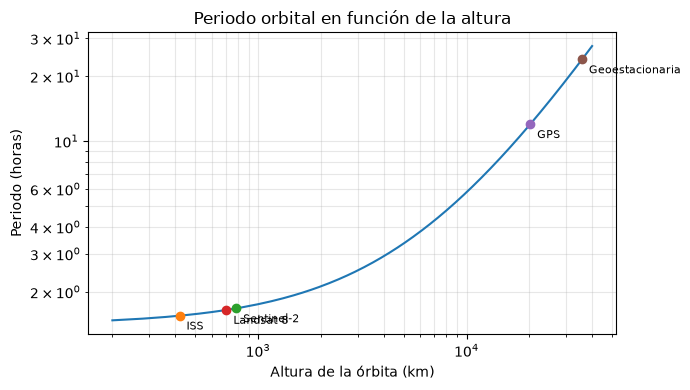

Landsat 8: velocidad 7.51 km/s, periodo 98.7 min, 14.59 órbitas por día, velocidad sobre el terreno 6.76 km/s
Sentinel-2: velocidad 7.46 km/s, periodo 100.4 min, 14.34 órbitas por día, velocidad sobre el terreno 6.64 km/s


In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 100

GM, R_T = 3.986e14, 6.371e6
H = np.linspace(200e3, 40000e3, 500)
P = 2 * np.pi * np.sqrt((R_T + H)**3 / GM)
fig, ax = plt.subplots(figsize=(7, 4))
ax.loglog(H / 1e3, P / 3600)
for nom, h_km in [('ISS', 420), ('Sentinel-2', 786), ('Landsat 8', 705), ('GPS', 20200), ('Geoestacionaria', 35786)]:
    p = 2 * np.pi * np.sqrt((R_T + h_km * 1e3)**3 / GM) / 3600
    ax.plot(h_km, p, 'o'); ax.annotate(nom, (h_km, p), textcoords='offset points', xytext=(5, -10), fontsize=8)
ax.set_xlabel('Altura de la órbita (km)'); ax.set_ylabel('Periodo (horas)')
ax.grid(alpha=0.3, which='both'); ax.set_title('Periodo orbital en función de la altura')
plt.tight_layout(); plt.show()

for nom, h_km in [('Landsat 8', 705), ('Sentinel-2', 786)]:
    r = R_T + h_km * 1e3
    v = np.sqrt(GM / r); p = 2 * np.pi * r / v
    print(f'{nom}: velocidad {v/1e3:.2f} km/s, periodo {p/60:.1f} min, {86400/p:.2f} órbitas por día, '
          f'velocidad sobre el terreno {v*R_T/r/1e3:.2f} km/s')

## Órbitas heliosincrónicas

La mayoría de los satélites ópticos usan órbitas heliosincrónicas: casi polares, con una inclinación cercana a 98°, de modo que el plano de la órbita rota alrededor del eje terrestre una vez al año, al mismo ritmo que la Tierra alrededor del Sol. Así el satélite pasa sobre cada latitud siempre a la misma hora solar local, por ejemplo hacia las 10:30 de la mañana en Landsat y Sentinel-2. Esto garantiza condiciones de iluminación comparables entre fechas, lo que facilita los estudios multitemporales, y la hora de la mañana se elige para evitar la nubosidad convectiva de la tarde.

Cada órbita tiene un tramo ascendente, en el que el satélite viaja de sur a norte, y uno descendente. Los sensores ópticos adquieren en el tramo diurno, que en Landsat y Sentinel-2 es el descendente. Los radares adquieren en ambos, y combinar las dos geometrías es útil para reducir las zonas de sombra y para separar los componentes vertical y este-oeste de la deformación del terreno.

## Franja de barrido y tiempo de revisita

La franja de barrido (swath) es el ancho de terreno que el sensor observa en una pasada: 185 km en Landsat 8 y 290 km en Sentinel-2. Mientras el satélite avanza, la Tierra gira debajo de él, y en el ecuador el terreno se desplaza unos 2750 km hacia el este entre dos órbitas consecutivas de Landsat. El tiempo de revisita, el intervalo entre dos observaciones del mismo punto con la misma geometría, depende del número de órbitas por ciclo y del ancho de la franja: 16 días para Landsat 8, 5 días para el par Sentinel-2A y 2B. En latitudes altas las franjas se traslapan y la revisita efectiva es más corta.

In [2]:
for nom, h_km, franja_km, ciclo_dias in [('Landsat 8', 705, 185, 16), ('Sentinel-2 (un satélite)', 786, 290, 10)]:
    r = R_T + h_km * 1e3
    p = 2 * np.pi * np.sqrt(r**3 / GM)
    desplaz = 2 * np.pi * R_T * p / 86164 / 1e3        # desplazamiento del ecuador entre órbitas (km)
    n_orb = round(ciclo_dias * 86400 / p)
    print(f'{nom}: desplazamiento entre órbitas {desplaz:.0f} km; {n_orb} órbitas en {ciclo_dias} días; '
          f'separación de trazas en el ecuador {2*np.pi*R_T/1e3/n_orb:.0f} km (franja {franja_km} km)')

Landsat 8: desplazamiento entre órbitas 2752 km; 233 órbitas en 16 días; separación de trazas en el ecuador 172 km (franja 185 km)
Sentinel-2 (un satélite): desplazamiento entre órbitas 2799 km; 143 órbitas en 10 días; separación de trazas en el ecuador 280 km (franja 290 km)


La celda siguiente dibuja de forma aproximada la traza sobre el terreno de algunas órbitas consecutivas de un satélite heliosincrónico, ignorando la precesión del plano orbital dentro de un mismo día.

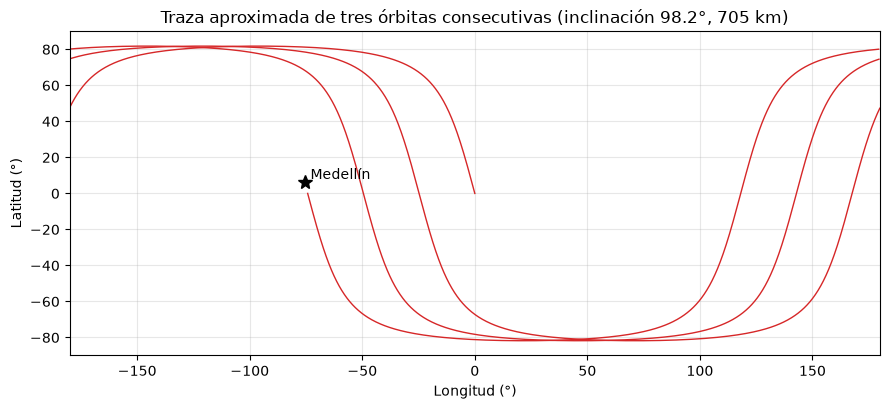

In [3]:
inc = np.radians(98.2)
r = R_T + 705e3
p = 2 * np.pi * np.sqrt(r**3 / GM)
t = np.linspace(0, 3 * p, 4000)
u = 2 * np.pi * t / p                                     # argumento de latitud
lat = np.degrees(np.arcsin(np.sin(inc) * np.sin(u)))
lon = np.degrees(np.arctan2(np.cos(inc) * np.sin(u), np.cos(u))) - 360 * t / 86164
lon = (lon + 180) % 360 - 180
fig, ax = plt.subplots(figsize=(9, 4.2))
salto = np.where(np.abs(np.diff(lon)) > 180)[0] + 1
for seg_lon, seg_lat in zip(np.split(lon, salto), np.split(lat, salto)):
    ax.plot(seg_lon, seg_lat, color='tab:red', lw=1)
ax.plot(-75.6, 6.25, 'k*', ms=10); ax.text(-73, 8, 'Medellín')
ax.set_xlim(-180, 180); ax.set_ylim(-90, 90); ax.grid(alpha=0.3)
ax.set_xlabel('Longitud (°)'); ax.set_ylabel('Latitud (°)')
ax.set_title('Traza aproximada de tres órbitas consecutivas (inclinación 98.2°, 705 km)')
plt.tight_layout(); plt.show()

## Sensores y detectores

Los sensores se clasifican, por la fuente de energía, en pasivos, que registran la radiación solar reflejada o la emitida por la superficie (cámaras, sensores multiespectrales y térmicos, radiómetros de microondas), y activos, que emiten su propia señal y miden el eco (radar, LiDAR, altímetros). Por la forma de registrar la información se distinguen los fotográficos, que usan película, y los electro-ópticos, que usan detectores electrónicos.

Los detectores pueden ser térmicos, que responden al calentamiento producido por la radiación absorbida, o cuánticos, en los que cada fotón libera electrones en un semiconductor. Los cuánticos son más sensibles y rápidos y son los que usan casi todos los sensores ópticos: el silicio en el visible y el infrarrojo cercano, y materiales como el InGaAs o el HgCdTe en el infrarrojo de onda corta y el térmico.

Hay tres formas de organizar los detectores para construir una imagen. En una cámara de cuadro (frame), una matriz bidimensional de detectores capta toda la escena a la vez, como en una cámara digital. En un barredor transversal (whiskbroom o across-track), un espejo oscilante recorre el terreno de lado a lado mientras el satélite avanza, y unos pocos detectores barren cada línea; es el diseño de los Landsat anteriores a Landsat 8. En un barredor de empuje (pushbroom o along-track), una línea de miles de detectores registra toda una fila del terreno a la vez y el avance del satélite completa la imagen; es el diseño de Landsat 8 y 9 (OLI) y de Sentinel-2 (MSI). El pushbroom no tiene partes móviles y cada detector observa el mismo punto más tiempo, lo que mejora la relación señal-ruido, pero exige calibrar miles de detectores entre sí; cuando la calibración no es perfecta aparece el bandeado que se corrige en el capítulo {doc}`10_Preprocesamiento`.

La celda siguiente compara, con números aproximados, el tiempo de permanencia (dwell time) de un detector sobre un píxel de 30 m en los dos diseños de barrido.

In [4]:
v_suelo = 6.76e3          # velocidad sobre el terreno, m/s
pix = 30.0
franja = 185e3
t_linea = pix / v_suelo   # tiempo para avanzar una línea
n_pix_linea = franja / pix
n_det_whisk = 16          # detectores por banda que barren a la vez (Landsat TM)
t_whisk = t_linea * n_det_whisk / n_pix_linea
print(f'Tiempo disponible por línea: {t_linea*1e3:.2f} ms')
print(f'Whiskbroom (16 detectores): {t_whisk*1e6:.1f} µs por píxel')
print(f'Pushbroom (un detector por columna): {t_linea*1e3:.2f} ms por píxel, {t_linea/t_whisk:.0f} veces más')

Tiempo disponible por línea: 4.44 ms
Whiskbroom (16 detectores): 11.5 µs por píxel
Pushbroom (un detector por columna): 4.44 ms por píxel, 385 veces más


## Para profundizar

El capítulo 4 de {cite}`lillesand2015` y el capítulo 3 de {cite}`chuvieco2008` describen las plataformas y los principales programas satelitales. Para órbitas y detectores, {cite:t}`tempfli2009` es una referencia clara y gratuita. Las especificaciones de cada misión se consultan en los manuales de usuario de Landsat 9 y de Sentinel-2 enlazados en la página del curso.